# Exoplanet Mass-Radius Analysis

## Research Question

How are exoplanet mass, radius, and density related, and what can
these relationships tell us about the physical properties of exoplanets?

## Data

Data are obtained from the NASA Exoplanet Archive's Planetary
Systems Composite Parameters (PSCompPars) table.

## Initial Variables

- Planet name
- Discovery method
- Orbital period
- Planet radius
- Planet mass
- Planet density

## Initial Hypothesis

For an object of constant density,

$$
M = \frac{4}{3}\pi\rho R^3
$$

and therefore

$$
M \propto R^3.
$$

We will investigate whether the observed exoplanet population
follows this relationship and how variations in density affect
the observed mass-radius relationship.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import requests

In [2]:
url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

params = {
    "query": """
        SELECT
            pl_name,
            discoverymethod,
            pl_orbper,
            pl_rade,
            pl_masse,
            pl_dens
        FROM pscomppars
    """,
    "format": "json"
}

response = requests.get(url, params=params)

response.raise_for_status()

data = response.json()

df = pd.DataFrame(data)

df.head()

,pl_name,discoverymethod,pl_orbper,pl_rade,pl_masse,pl_dens
0,HD 80653 b,Transit,0.719579,1.621000,5.610000,7.24
1,K2-312 c,Radial Velocity,871.320000,12.800000,NaN,4.41
2,XO-2 S d,Radial Velocity,4696.000000,13.000000,NaN,2.95
3,Kepler-1808 b,Transit,23.340401,3.025113,NaN,1.87
4,Kepler-418 b,Transit,86.678560,13.450000,349.611248,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6336 entries, 0 to 6335
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6336 non-null   object 
 1   discoverymethod  6336 non-null   object 
 2   pl_orbper        5992 non-null   float64
 3   pl_rade          6286 non-null   float64
 4   pl_masse         2424 non-null   float64
 5   pl_dens          6195 non-null   float64
dtypes: float64(4), object(2)
memory usage: 297.1+ KB


In [5]:
df.describe()

,pl_orbper,pl_rade,pl_masse,pl_dens
count,5.992000e+03,6286.000000,2424.000000,6195.000000
mean,7.144464e+04,5.851832,812.081117,4.842763
std,5.195691e+06,5.422517,1593.608091,34.047999
min,9.070629e-02,0.309800,0.020000,0.005100
25%,4.308908e+00,1.850000,11.297500,1.270000
50%,1.074551e+01,2.860000,158.915000,2.520000
75%,3.856275e+01,11.915990,723.573125,4.540000
max,4.020000e+08,87.205870,9534.852210,2000.000000


In [6]:
df.isna().sum()

pl_name               0
discoverymethod       0
pl_orbper           344
pl_rade              50
pl_masse           3912
pl_dens             141
dtype: int64

In [8]:
mass_data = df.dropna(subset=["pl_masse", "pl_rade"])

print("Planets with both mass and radius:", len(mass_data))

Planets with both mass and radius: 2383


In [9]:
mass_radius_density = df.dropna(
    subset=["pl_masse", "pl_rade", "pl_dens"]
)

print("Planets with mass, radius, and reported density:",
      len(mass_radius_density))

Planets with mass, radius, and reported density: 2315


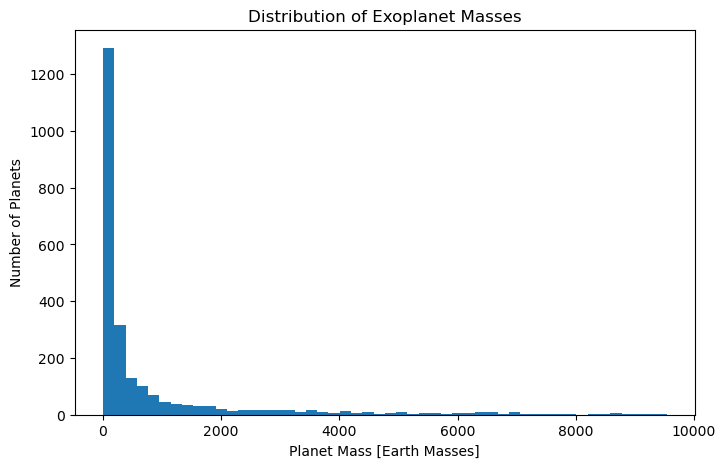

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(
    mass_data["pl_masse"],
    bins=50
)

plt.xlabel("Planet Mass [Earth Masses]")
plt.ylabel("Number of Planets")
plt.title("Distribution of Exoplanet Masses")

plt.show()

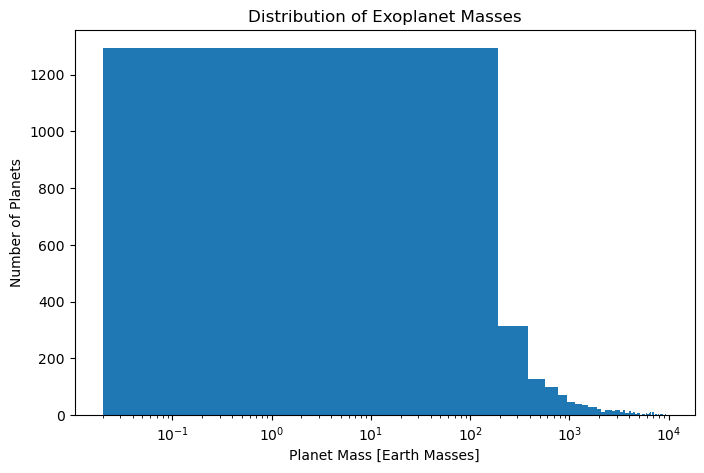

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(
    mass_data["pl_masse"],
    bins=50
)

plt.xscale("log")

plt.xlabel("Planet Mass [Earth Masses]")
plt.ylabel("Number of Planets")
plt.title("Distribution of Exoplanet Masses")

plt.show()

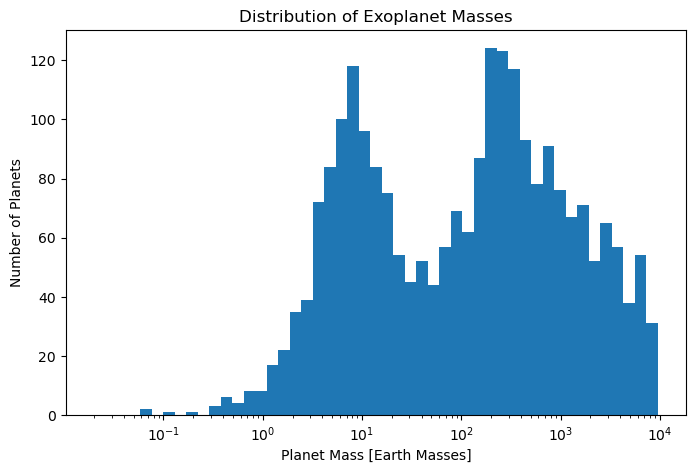

In [16]:
mass = mass_data["pl_masse"]

bins = np.logspace(
    np.log10(mass.min()),
    np.log10(mass.max()),
    50
)

plt.figure(figsize=(8, 5))

plt.hist(mass, bins=bins)

plt.xscale("log")

plt.xlabel("Planet Mass [Earth Masses]")
plt.ylabel("Number of Planets")
plt.title("Distribution of Exoplanet Masses")

plt.show()

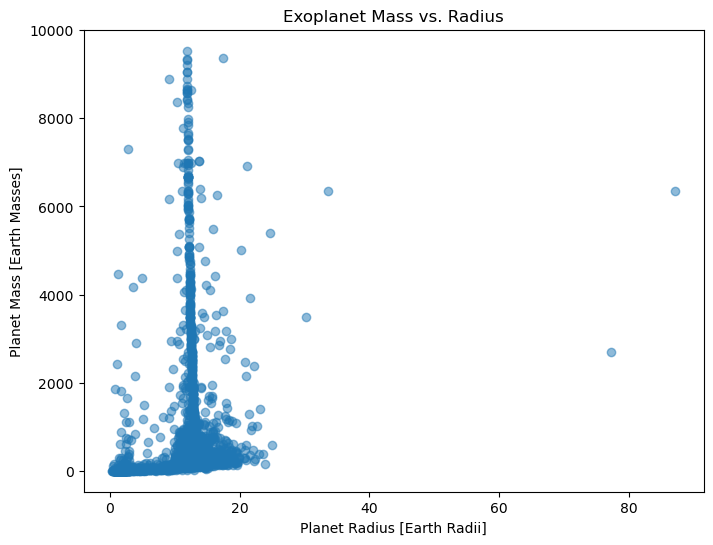

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    mass_data["pl_rade"],
    mass_data["pl_masse"],
    alpha=0.5
)

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Planet Mass [Earth Masses]")
plt.title("Exoplanet Mass vs. Radius")

plt.show()

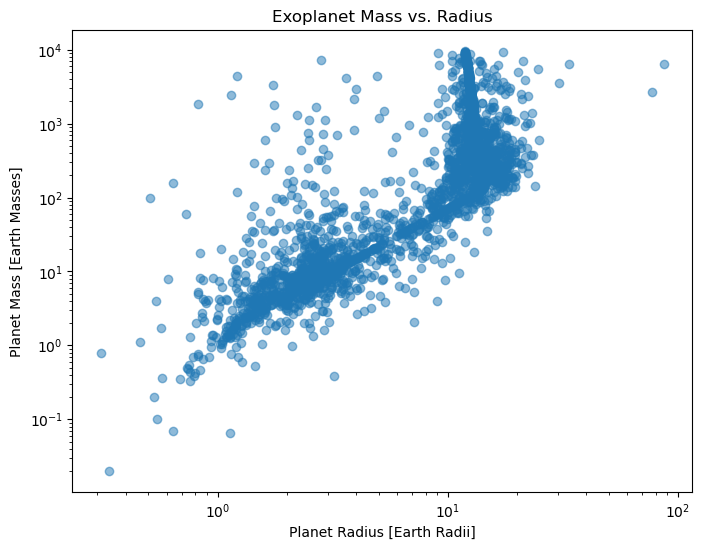

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(
    mass_data["pl_rade"],
    mass_data["pl_masse"],
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Planet Mass [Earth Masses]")
plt.title("Exoplanet Mass vs. Radius")

plt.show()

In [19]:
log_radius = np.log10(mass_data["pl_rade"])
log_mass = np.log10(mass_data["pl_masse"])

In [20]:
slope, intercept, r_value, p_value, std_err = stats.linregress(
    log_radius,
    log_mass
)

print("Slope:", slope)
print("Intercept:", intercept)
print("R²:", r_value**2)
print("p-value:", p_value)
print("Standard error:", std_err)

Slope: 2.178787004557987
Intercept: 0.25175957849704456
R²: 0.6819862906199239
p-value: 0.0
Standard error: 0.030490895362727265


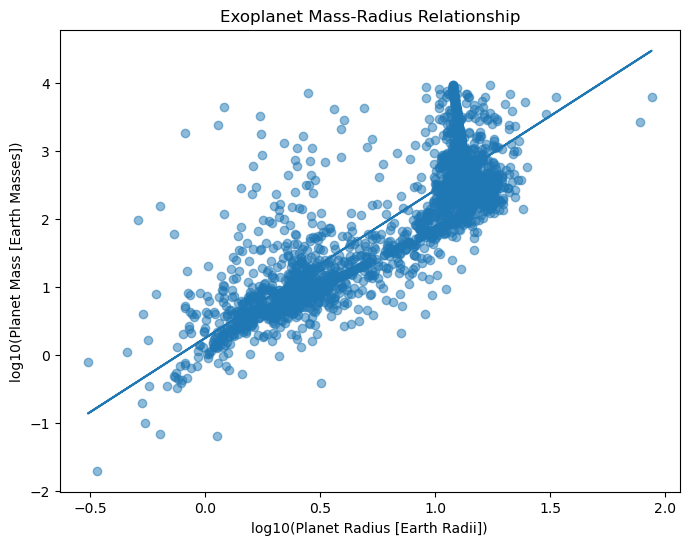

In [21]:
plt.figure(figsize=(8, 6))

plt.scatter(
    log_radius,
    log_mass,
    alpha=0.5
)

plt.plot(
    log_radius,
    slope * log_radius + intercept
)

plt.xlabel("log10(Planet Radius [Earth Radii])")
plt.ylabel("log10(Planet Mass [Earth Masses])")
plt.title("Exoplanet Mass-Radius Relationship")

plt.show()

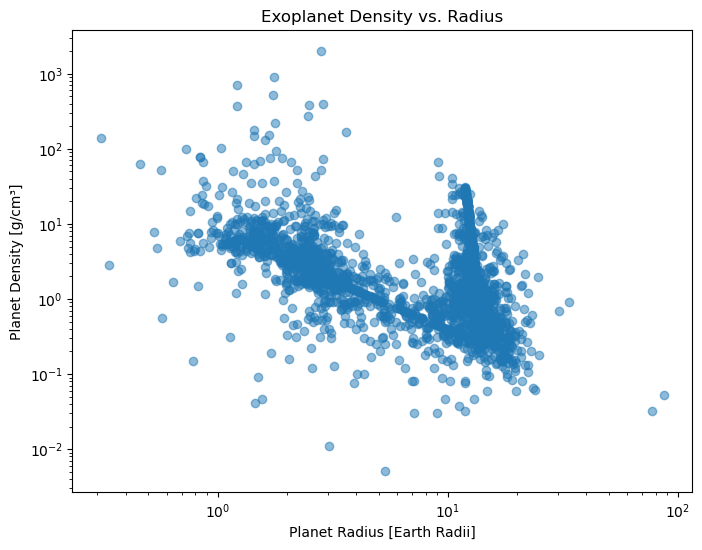

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(
    mass_radius_density["pl_rade"],
    mass_radius_density["pl_dens"],
    alpha=0.5
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Planet Density [g/cm³]")
plt.title("Exoplanet Density vs. Radius")

plt.show()

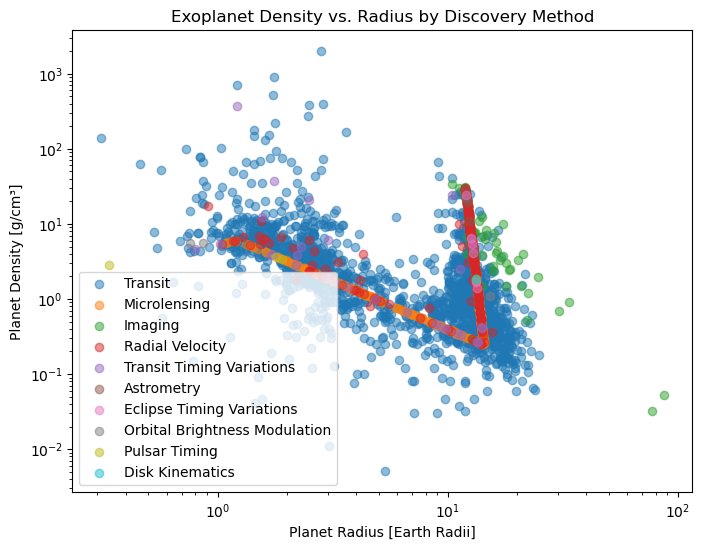

In [23]:
plt.figure(figsize=(8, 6))

for method in mass_radius_density["discoverymethod"].unique():

    subset = mass_radius_density[
        mass_radius_density["discoverymethod"] == method
    ]

    plt.scatter(
        subset["pl_rade"],
        subset["pl_dens"],
        alpha=0.5,
        label=method
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Planet Density [g/cm³]")
plt.title("Exoplanet Density vs. Radius by Discovery Method")

plt.legend()

plt.show()

In [24]:
mass_radius_density["discoverymethod"].value_counts()

discoverymethod
Transit                          1599
Radial Velocity                   287
Microlensing                      282
Imaging                            93
Transit Timing Variations          33
Eclipse Timing Variations           7
Astrometry                          6
Pulsar Timing                       4
Orbital Brightness Modulation       3
Disk Kinematics                     1
Name: count, dtype: int64

In [26]:
methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]

for method in methods:

    subset = mass_radius_density[
        mass_radius_density["discoverymethod"] == method
    ].dropna(subset=["pl_rade", "pl_dens"])

    log_r = np.log10(subset["pl_rade"])
    log_d = np.log10(subset["pl_dens"])

    slope, intercept, r_value, p_value, std_err = stats.linregress(
        log_r,
        log_d
    )

    print(method)
    print("  N =", len(subset))
    print("  slope =", slope)
    print("  intercept =", intercept)
    print("  R² =", r_value**2)
    print("  standard error =", std_err)
    print()

Transit
  N = 1599
  slope = -0.963263447923514
  intercept = 0.9013499483858861
  R² = 0.38755076917328507
  standard error = 0.030301446990691816

Radial Velocity
  N = 287
  slope = 0.0003642972665076163
  intercept = 0.6071880278128731
  R² = 3.769094735147754e-08
  standard error = 0.11115140266835587

Microlensing
  N = 282
  slope = -0.3622405080511634
  intercept = 0.4840388279059884
  R² = 0.04748646695162497
  standard error = 0.09695465081822235

Imaging
  N = 93
  slope = -3.11066578381954
  intercept = 4.430604292386279
  R² = 0.6995173137967605
  standard error = 0.21371900736240326



In [27]:
methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]

for method in methods:

    subset = mass_data[
        mass_data["discoverymethod"] == method
    ].dropna(subset=["pl_rade", "pl_masse"])

    log_r = np.log10(subset["pl_rade"])
    log_m = np.log10(subset["pl_masse"])

    slope, intercept, r_value, p_value, std_err = stats.linregress(
        log_r,
        log_m
    )

    print(method)
    print("  N =", len(subset))
    print("  slope =", slope)
    print("  intercept =", intercept)
    print("  R² =", r_value**2)
    print("  standard error =", std_err)
    print()

Transit
  N = 1664
  slope = 1.8650003590498867
  intercept = 0.371055845469596
  R² = 0.6757940812677004
  standard error = 0.0316859467248375

Radial Velocity
  N = 289
  slope = 2.9278614144231185
  intercept = -0.0539535922806027
  R² = 0.7211083447884468
  standard error = 0.10747985383022667

Microlensing
  N = 282
  slope = 2.637789856922082
  intercept = -0.25595753717540193
  R² = 0.7254716605526564
  standard error = 0.09697159607466586

Imaging
  N = 94
  slope = -0.11925528894825864
  intercept = 3.703463852007388
  R² = 0.003385502591754687
  standard error = 0.2133220557439186



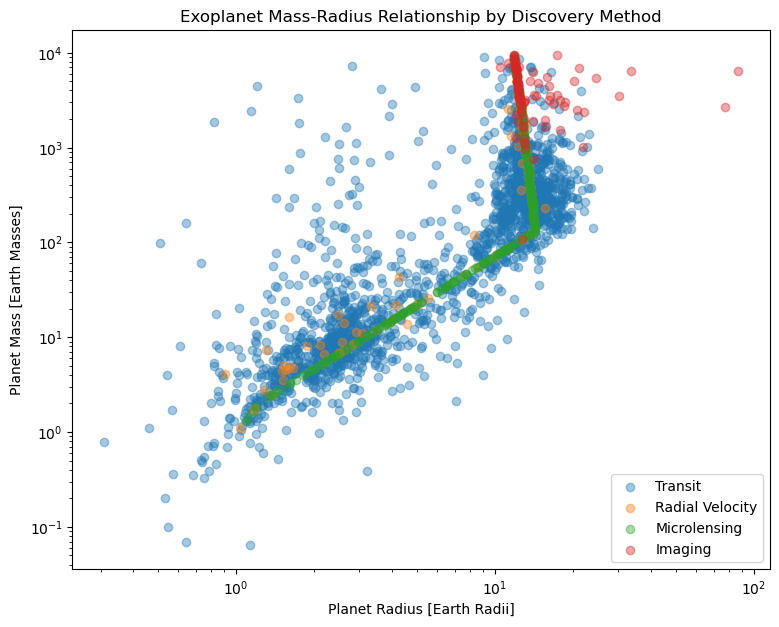

In [28]:
methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]

plt.figure(figsize=(9, 7))

for method in methods:

    subset = mass_data[
        mass_data["discoverymethod"] == method
    ].dropna(subset=["pl_rade", "pl_masse"])

    plt.scatter(
        subset["pl_rade"],
        subset["pl_masse"],
        alpha=0.4,
        label=method
    )

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Planet Mass [Earth Masses]")
plt.title("Exoplanet Mass-Radius Relationship by Discovery Method")

plt.legend()

plt.show()

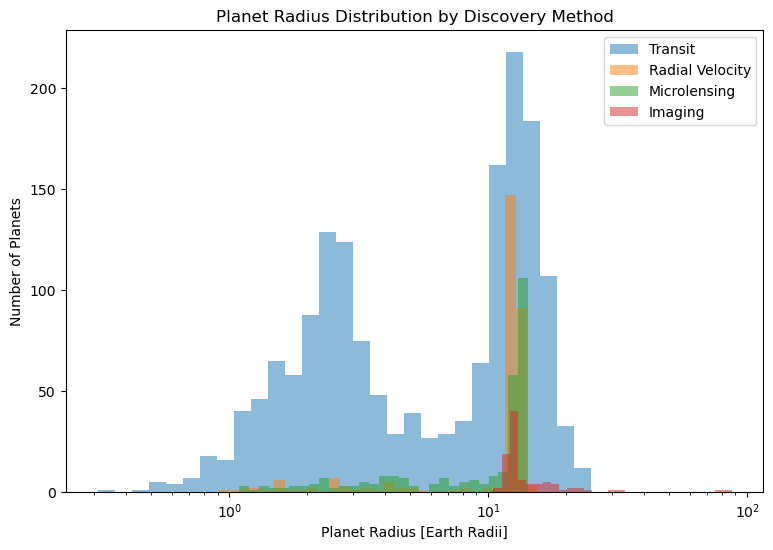

In [29]:
plt.figure(figsize=(9, 6))

for method in methods:

    subset = mass_data[
        mass_data["discoverymethod"] == method
    ]["pl_rade"].dropna()

    plt.hist(
        subset,
        bins=np.logspace(
            np.log10(subset.min()),
            np.log10(subset.max()),
            30
        ),
        alpha=0.5,
        label=method
    )

plt.xscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Number of Planets")
plt.title("Planet Radius Distribution by Discovery Method")

plt.legend()

plt.show()

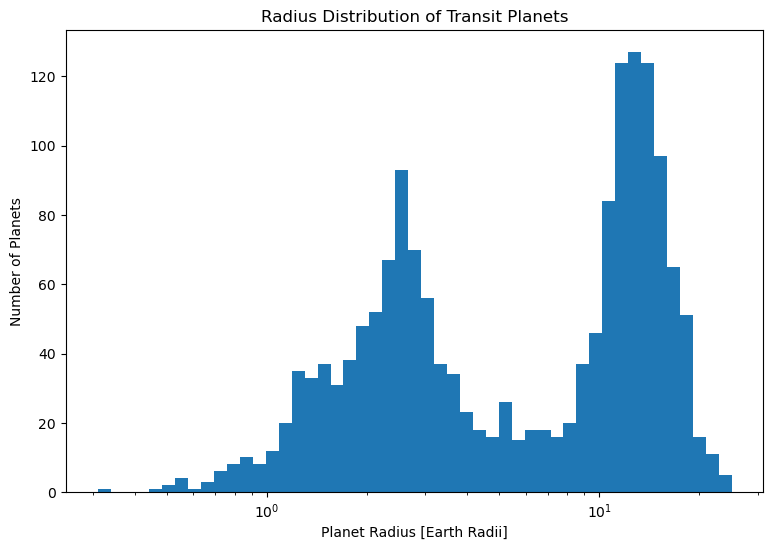

In [30]:
transit = mass_data[
    mass_data["discoverymethod"] == "Transit"
]["pl_rade"].dropna()

plt.figure(figsize=(9, 6))

plt.hist(
    transit,
    bins=np.logspace(
        np.log10(transit.min()),
        np.log10(transit.max()),
        50
    )
)

plt.xscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Number of Planets")
plt.title("Radius Distribution of Transit Planets")

plt.show()

In [31]:
print(transit.describe())

count    1664.000000
mean        7.906672
std         5.804775
min         0.309800
25%         2.430000
50%         6.919113
75%        12.814689
max        25.000000
Name: pl_rade, dtype: float64


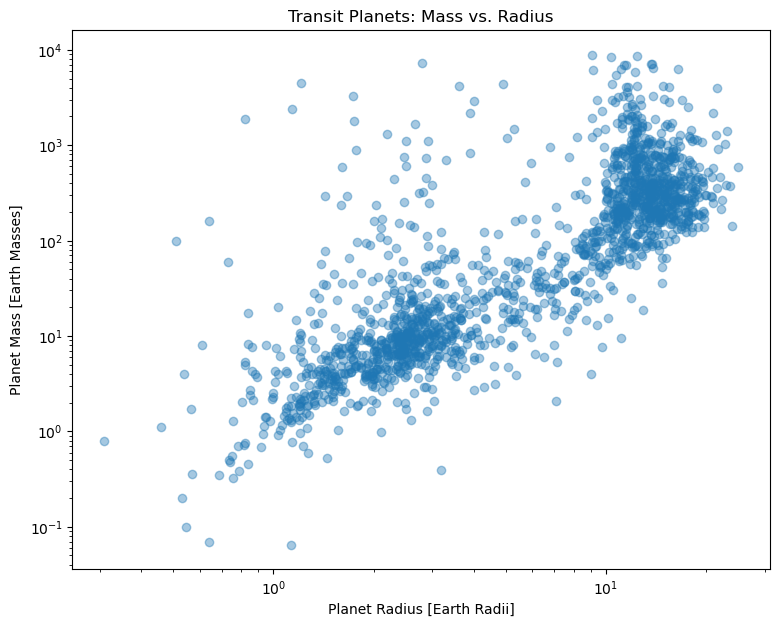

In [32]:
plt.figure(figsize=(9, 7))

subset = mass_data[
    mass_data["discoverymethod"] == "Transit"
].dropna(subset=["pl_rade", "pl_masse"])

plt.scatter(
    subset["pl_rade"],
    subset["pl_masse"],
    alpha=0.4
)

plt.xscale("log")
plt.yscale("log")

plt.xlabel("Planet Radius [Earth Radii]")
plt.ylabel("Planet Mass [Earth Masses]")
plt.title("Transit Planets: Mass vs. Radius")

plt.show()